# Processamento de imagens em Python
## INF0417 - Visão computacional

# 1. Introdução
Em python precisamos importar os pacotes que forneçam a funcionalidade que queremos.

Nesta disciplina vamos fazer uso de pacotes como `numpy`, `scipy` e `matplotlib`.

Comecemos importando eles.

In [1]:
import numpy as np
import scipy
from matplotlib import pyplot as plt
import sys

# plt.rcParams['figure.figsize'] = (10, 10)

In [2]:
'''
Choose your Lib path
'''
import os

try:
    from google.colab import drive

    drive.mount('/content/drive')
    # Google Colab
    LIB_PATH = '/content/drive/MyDrive/'

except ImportError:
    # Laptop / Desktop / Android / Windows / macOS:
    # procura a pasta 'lib' na pasta do notebook e nas pastas acima dela
    # (a versao original usava `!uname -m`, que nao existe no Windows)
    LIB_PATH = '.'
    for candidate in ['.', '..', '../..']:
        if os.path.isdir(os.path.join(candidate, 'lib')):
            LIB_PATH = os.path.abspath(candidate)
            break

sys.path.append(LIB_PATH)

In [3]:
try:
    from lib.myPlotLib import *
except ImportError:
    pass

# Se a myPlotLib disponivel nao tiver SIGNALplot, usamos esta versao
if 'SIGNALplot' not in globals():
    def SIGNALplot(x, n=None, xlim=None):
        '''
        Plota o sinal x contra o eixo n (amostras, tempo ou frequencia).
        Usa stem para poucos pontos e linha continua para muitos.
        '''
        x = np.asarray(x)
        n = np.arange(len(x)) if n is None else np.asarray(n)

        fig, ax = plt.subplots(figsize=(10, 3.5))
        if len(x) <= 300:
            ax.stem(n, x, linefmt='r-', markerfmt='ro', basefmt='k-')
        else:
            ax.plot(n, x, 'r')
        if xlim is not None:
            ax.set_xlim(xlim)
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        plt.show()

In [4]:
# This instruction can only be used with IPython Notebook
%matplotlib inline

`numpy` nos permite trabalhar com `num`eros em `py`thon!

Ele é ótimo para trabalhar com vetores e matrizes.

Vamos ver como criar um vetor:

In [5]:
vetor1 = np.array([[1, 2, 3]], dtype=float)

vetor2 = np.array([1, 2, 3], dtype=float)[:, np.newaxis]

vetor3 = np.expand_dims(np.array([1, 2, 3], dtype=float), 1)

Mostre a saída de cada vetor e comente os seus achados

In [6]:
# Aqui sua resposta
for nome, v in [('vetor1', vetor1), ('vetor2', vetor2), ('vetor3', vetor3)]:
    print(nome, '- shape:', v.shape, '- ndim:', v.ndim)
    print(v, '\n')

vetor1 - shape: (1, 3) - ndim: 2
[[1. 2. 3.]] 

vetor2 - shape: (3, 1) - ndim: 2
[[1.]
 [2.]
 [3.]] 

vetor3 - shape: (3, 1) - ndim: 2
[[1.]
 [2.]
 [3.]] 



**Resposta:**

- `vetor1` tem `shape (1, 3)`: é uma matriz de **1 linha e 3 colunas** (vetor linha). Os colchetes duplos `[[...]]` criam duas dimensões.
- `vetor2` tem `shape (3, 1)`: o `[:, np.newaxis]` acrescenta um eixo novo **depois** do eixo original, o que resulta em **3 linhas e 1 coluna** (vetor coluna).
- `vetor3` tem `shape (3, 1)`: `np.expand_dims(..., 1)` faz exatamente o mesmo que `[:, np.newaxis]`, então `vetor2` e `vetor3` são idênticos.

Um array 1-D comum, `np.array([1, 2, 3])`, tem `shape (3,)`, que **não é** linha nem coluna. Para fazer contas de matrizes, como `@`, precisamos dizer explicitamente qual é qual.

Tudo em `numpy` é um arranjo ou *array*, e arranjos têm:

- `dtype`: Descreve o tipo de números presentes no arranjo (*e.g.*, `float`, `int`, `bool`)

- `shape`: Descreve as dimensões do arranjo

- `size`: Descreve o tamanho do arranjo (número de elementos no array)

In [7]:
vetor1.dtype

dtype('float64')

In [8]:
vetor1.shape

(1, 3)

In [9]:
vetor1.size

3

# 2. Operações
Podemos **somar** e **subtrair** matrizes facilmente:

In [10]:
vetor1 + vetor1

array([[2., 4., 6.]])

In [11]:
vetor1 - vetor1

array([[0., 0., 0.]])

E quanto à **multiplicação de matrizes**?

In [12]:
vetor1 @ (vetor1.T) # Multiplicacao de matrices, o mesmo que o operador * no MATLAB

array([[14.]])

E à **multiplicação elemento a elemento** (*i.e.*, [o produto de Hadamard](https://en.wikipedia.org/wiki/Hadamard_product_(matrices)))?

In [13]:
vetor1 * vetor1 # Multiplicação elemento a elemento, o mesmo que o operador .* no MATLAB

array([[1., 4., 9.]])

**Responda**: O que `.T` faz com um arranjo?

In [14]:
# Aqui sua resposta
A = np.array([[1, 2, 3],
              [4, 5, 6]])

print(A, A.shape)
print(A.T, A.T.shape)                       # linhas viram colunas e colunas viram linhas
print(vetor1.shape, '->', vetor1.T.shape)   # (1, 3) -> (3, 1)
print(np.array([1, 2, 3]).T.shape)          # array 1-D: .T nao faz nada

[[1 2 3]
 [4 5 6]] (2, 3)
[[1 4]
 [2 5]
 [3 6]] (3, 2)
(1, 3) -> (3, 1)
(3,)


**Resposta:** `.T` é a **transposta**: troca linhas por colunas, de modo que um elemento `A[i, j]` passa para a posição `A.T[j, i]`. Um `shape (m, n)` vira `(n, m)`, e um vetor linha `(1, 3)` vira vetor coluna `(3, 1)`.
Isso explica `vetor1 @ vetor1.T`, que é $(1\times3)\cdot(3\times1) = (1\times1)$ e dá o produto escalar $1+4+9=14$. Em um array 1-D, `.T` não tem efeito, pois ele só tem um eixo.

Basicamente, podemos realizar muitas operações matemáticas chamando a função `numpy` apropriada:

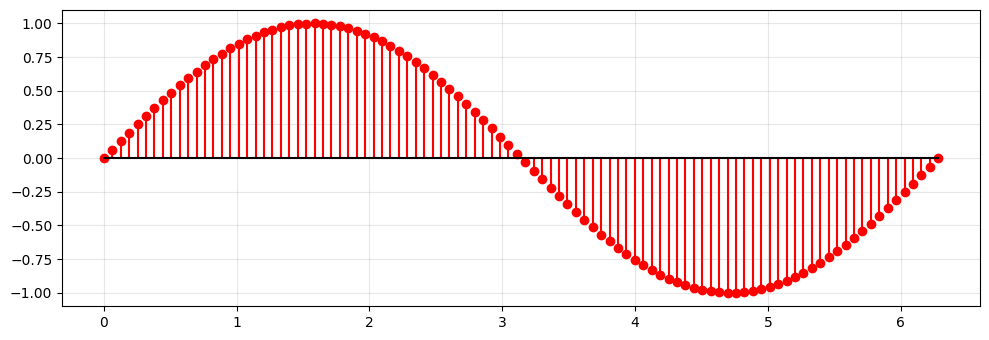

In [15]:
x = np.linspace(0, 2*np.pi, num=100)
y = np.sin(x)

SIGNALplot(y, x)

## 2.1 Indexação

No caso mais simples, queremos acessar um único índice do vetor:

In [16]:
ind = 0 # Arranjos começam no índice 0 (!)
x[ind]

np.float64(0.0)

Também podemos querer os primeiros 10 elementos. \
Isso se chama **fatiar**

In [17]:
x[0:10]

array([0.        , 0.06346652, 0.12693304, 0.19039955, 0.25386607,
       0.31733259, 0.38079911, 0.44426563, 0.50773215, 0.57119866])

Também podemos querer recuperar cada segundo índice:

In [18]:
x[::2] # Abreviação de x[0: -1: 2], onde -1 é a abreviação de "o último elemento de x"

array([0.        , 0.12693304, 0.25386607, 0.38079911, 0.50773215,
       0.63466518, 0.76159822, 0.88853126, 1.01546429, 1.14239733,
       1.26933037, 1.3962634 , 1.52319644, 1.65012947, 1.77706251,
       1.90399555, 2.03092858, 2.15786162, 2.28479466, 2.41172769,
       2.53866073, 2.66559377, 2.7925268 , 2.91945984, 3.04639288,
       3.17332591, 3.30025895, 3.42719199, 3.55412502, 3.68105806,
       3.8079911 , 3.93492413, 4.06185717, 4.1887902 , 4.31572324,
       4.44265628, 4.56958931, 4.69652235, 4.82345539, 4.95038842,
       5.07732146, 5.2042545 , 5.33118753, 5.45812057, 5.58505361,
       5.71198664, 5.83891968, 5.96585272, 6.09278575, 6.21971879])

**Tarefa 2**: Agora queremos obter cada terceiro índice de $\Large x$, começando no quinto índice. Forneça o comando apropriado abaixo:

In [19]:
# Aqui sua resposta
x = np.linspace(0, 2*np.pi, num=100)   # o x original (a celula da indexacao 2D mais abaixo o redefine)
x[4::3]    # comeca no quinto elemento (indice 4) e anda de 3 em 3

array([0.25386607, 0.44426563, 0.63466518, 0.82506474, 1.01546429,
       1.20586385, 1.3962634 , 1.58666296, 1.77706251, 1.96746207,
       2.15786162, 2.34826118, 2.53866073, 2.72906028, 2.91945984,
       3.10985939, 3.30025895, 3.4906585 , 3.68105806, 3.87145761,
       4.06185717, 4.25225672, 4.44265628, 4.63305583, 4.82345539,
       5.01385494, 5.2042545 , 5.39465405, 5.58505361, 5.77545316,
       5.96585272, 6.15625227])

**Resposta:** `x[4::3]`. A sintaxe é `x[início:fim:passo]`: o quinto elemento tem índice **4** (a contagem começa em 0), o fim vazio significa "até o último" e o passo é 3. Pega os índices 4, 7, 10, 13, ...

## 2.2 Indexação Booleana

Digamos que queremos pegar todos os valores de $\Large x$, onde $\Large y<0$.

Então podemos usar a **indexação booleana**, e é super simples!

In [20]:
x[y < 0]

array([3.17332591, 3.23679243, 3.30025895, 3.36372547, 3.42719199,
       3.4906585 , 3.55412502, 3.61759154, 3.68105806, 3.74452458,
       3.8079911 , 3.87145761, 3.93492413, 3.99839065, 4.06185717,
       4.12532369, 4.1887902 , 4.25225672, 4.31572324, 4.37918976,
       4.44265628, 4.5061228 , 4.56958931, 4.63305583, 4.69652235,
       4.75998887, 4.82345539, 4.88692191, 4.95038842, 5.01385494,
       5.07732146, 5.14078798, 5.2042545 , 5.26772102, 5.33118753,
       5.39465405, 5.45812057, 5.52158709, 5.58505361, 5.64852012,
       5.71198664, 5.77545316, 5.83891968, 5.9023862 , 5.96585272,
       6.02931923, 6.09278575, 6.15625227, 6.21971879, 6.28318531])

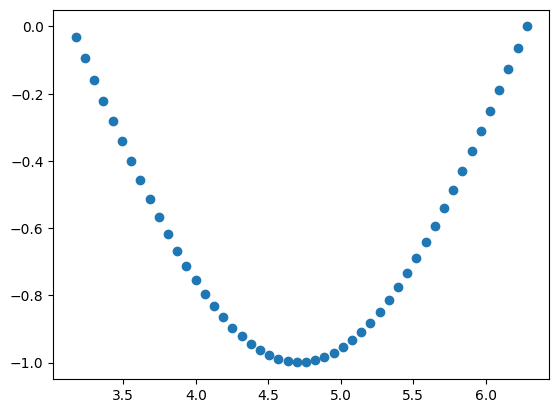

In [21]:
plt.scatter(x[y < 0], y[y < 0])
plt.show()

**Tarefa 3**: Agora queremos indexar todos os valores de $\Large (x,y)$ de forma que $\Large y^2 < 0.5$. Forneça o código apropriado abaixo.

50 de 100 pontos selecionados


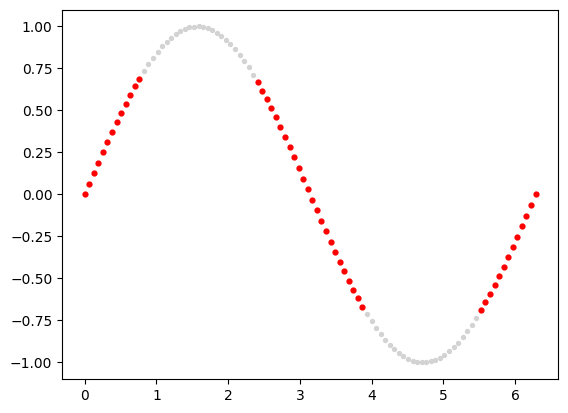

In [22]:
# Aqui sua resposta
x = np.linspace(0, 2*np.pi, num=100)
y = np.sin(x)

mask = y**2 < 0.5            # vetor booleano: True onde y^2 < 0.5
x_sel, y_sel = x[mask], y[mask]
print(mask.sum(), 'de', len(x), 'pontos selecionados')

plt.scatter(x, y, s=8, c='lightgray')   # todos os pontos
plt.scatter(x_sel, y_sel, s=12, c='r')  # apenas os selecionados
plt.show()

**Resposta:** `y**2 < 0.5` equivale a $|y| < 0{,}707$, então são selecionados os pontos próximos dos cruzamentos por zero da senoide (em vermelho), e ficam de fora os picos e vales.

## 2.3 Indexação multidimensional

A indexação funciona basicamente da mesma forma!

In [23]:
x = np.array([[1,2,3], \
              [4,5,6], \
              [7,8,9]])
y = x[ 0:2, \
      0:2 ] # Selecionar um bloco 2x2

print(x)
print(y)

[[1 2 3]
 [4 5 6]
 [7 8 9]]
[[1 2]
 [4 5]]


## 2.4 Imagens

Felizmente para nós, imagens são arranjos (*arrays*), então os comandos acima também aplicam a imagens!

Iremos apresentar algumas maneiras de carregar imagens em python.

Começamos usando `matplotlib` para carregar uma imagem.

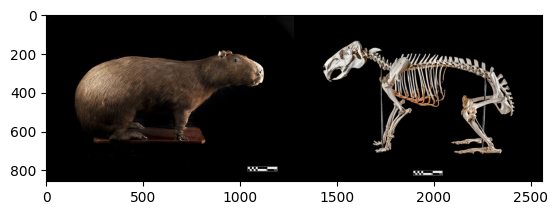

In [24]:
image_mpl = plt.imread('capybaras.png')

plt.imshow(image_mpl) # Mostra algumas capivaras
plt.show()

Outra maneira é com a biblioteca **OpenCV**.

A imagem é automaticamente transformada em uma matriz `numpy`, porém com um modelo de cor BGR em vez de RGB.

In [25]:
# ! pip install opencv-python opencv-contrib-python scikit-image # Image Processing, Computer Vision

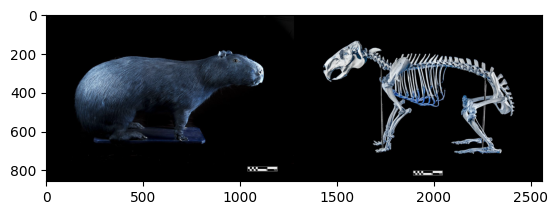

In [26]:
import cv2

image_cv2 = cv2.imread('capybaras.png')
plt.imshow(image_cv2) # Agora as capivaras são azuis, pois o OpenCV usa BGR em vez de RGB
plt.show()

Também podemos usar **PIL**

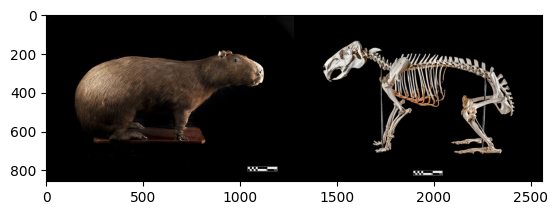

In [27]:
from PIL import Image

image_pil = Image.open('capybaras.png')


plt.imshow(image_pil)
plt.show()

A imagem não é transformada em um array `numpy` automaticamente, mas podemos convertê-la facilmente :)

In [28]:
print(image_pil)

<PIL.PngImagePlugin.PngImageFile image mode=RGBA size=2560x857 at 0x1D77FC2B110>


In [29]:
image_pil = np.array(image_pil) # Converte um objeto PIL em um array numpy
print(image_pil)

[[[  1   1   1 255]
  [  0   0   0 255]
  [  0   0   0 255]
  ...
  [  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]]

 [[  1   1   1 255]
  [  0   0   0 255]
  [  0   0   0 255]
  ...
  [  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]]

 [[  2   2   2 255]
  [  1   1   1 255]
  [  1   1   1 255]
  ...
  [  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]]

 ...

 [[  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]
  ...
  [  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]]

 [[  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]
  ...
  [  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]]

 [[  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]
  ...
  [  0   0   0 255]
  [  0   0   0 255]
  [  0   0   0 255]]]


**Tarefa 4**: Qual é o tipo de dado da imagem no OpenCV e no PIL e quais as suas dimensões? \
Quais são os valores das intensidades máxima e mínima?

In [30]:
for nome, img in [('OpenCV', image_cv2), ('PIL', np.array(Image.open('capybaras.png')))]:
    print(f'{nome:6s} dtype={img.dtype}  shape={img.shape}  min={img.min()}  max={img.max()}')
print(f'Matplotlib (plt.imread) dtype={image_mpl.dtype}  shape={image_mpl.shape}  '
      f'min={image_mpl.min()}  max={image_mpl.max()}')

OpenCV dtype=uint8  shape=(857, 2560, 3)  min=0  max=255
PIL    dtype=uint8  shape=(857, 2560, 4)  min=0  max=255
Matplotlib (plt.imread) dtype=float32  shape=(857, 2560, 4)  min=0.0  max=1.0


**Resposta**:

| Biblioteca | dtype | shape (altura, largura, canais) | mínimo | máximo |
|---|---|---|---|---|
| OpenCV | `uint8` | (857, 2560, **3**), ordem **BGR** | 0 | 255 |
| PIL | `uint8` | (857, 2560, **4**), ordem **RGBA** | 0 | 255 |

Os dois usam `uint8`, com intensidades de 0 a 255. A diferença está nos canais: o `cv2.imread` descarta o canal alfa (transparência) por padrão e devolve 3 canais, enquanto o PIL mantém os 4 canais do PNG. (O `plt.imread` devolve `float32` normalizado em [0, 1].)

# 3. Criando um filtro 2D

Muitas das vezes queremos "filtrar" nossas imagens como parte do processamento.

Mas, o que é *filtrar*?

Vamos criar um filtro Gaussiano de *desfoque* (*Gaussian blur*) com a `numpy`!

Um filtro Gaussiano age como filtro passa-baixa (*low-pass filter*) ou fitro de *smoothing*, pois ele filtra as frequências altas presentes na imagem.

In [31]:
kernel_size = 13

coords = np.linspace(-(kernel_size//2), kernel_size//2, num=kernel_size) # Vetor de coordenadas do filtro de tamanho N=kernel_size
(x, y) = np.meshgrid(coords, coords)

Acabamos de criar um *meshgrid*, isto é, uma malha ou grade com as coordenadas 2D dos valores do filtro

Você pode pensar nele como um array contendo todas as coordenadas $\Large (x, y)$ do filtro.

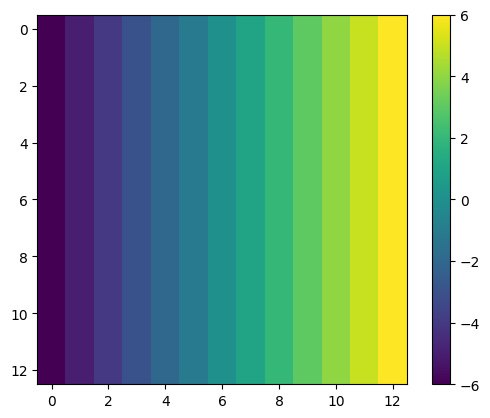

In [32]:
plt.imshow(x) # Observe que o eixo x cresce para a direita
plt.colorbar()
plt.show()

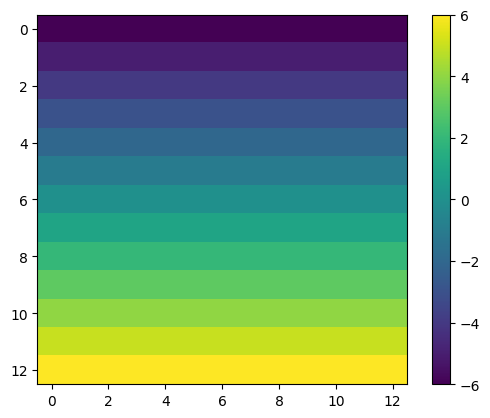

In [33]:
plt.imshow(y) # Observe que o eixo y cresce para baixo!
plt.colorbar()
plt.show()

Agora vamos a criar um filtro Gaussiano nesta grade!

**Tarefa**: A equação de um filtro Gaussiano é:

$$
\Large \exp \left( \frac{-(x^2+y^2)}{2\sigma^2} \right)
$$

Como você escreveria a equação do filtro em `numpy`?
Escreva o código abaixo.

*Dica*: Em `numpy`, $\Large \exp(\cdot)$ pode ser escrito como `np.exp()` e $\Large x^2$ pode ser escrito como `x**2`

In [34]:
# Responda aqui
sigma = 3.5
lp_filter = np.exp(-(x**2 + y**2) / (2 * sigma**2))  # Filtro Gaussiano 2-D

Além disso, queremos normalizar o filtro e que some 1, para garantir que a imagem não fique super clara ou escura no processamento!

In [35]:
lp_filter = lp_filter / np.sum(lp_filter) # Filtro Gaussiano normalizado 2-D

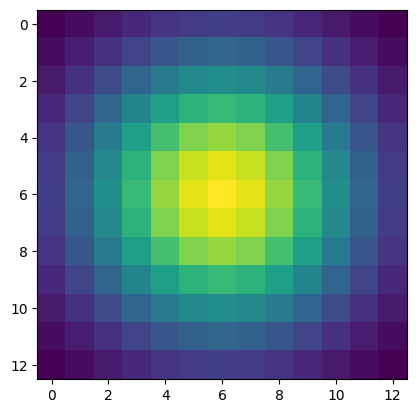

In [36]:
plt.imshow(lp_filter)
plt.show()

# 4. Convolvendo nosso filtro com a imagem

Agora que (com um pouco de sorte) temos um filtro passa-baixa funcionando, vamos realizar o [processo de filtragem da imagem](https://en.wikipedia.org/wiki/Kernel_(image_processing)) pela convolução do nosso filtro com a imagem da capivara!

Primeiro, vamos importar a função `conv2` do pacote `scipy` para realizar a [**convolução**](https://en.wikipedia.org/wiki/Convolution)

In [37]:
from scipy.signal import convolve2d as conv2

Agora vamos fazer a convolução!

In [38]:
try:
    image_lp = conv2(image_pil, lp_filter, mode='same')
except ValueError as e:
    # conv2 so aceita arrays 2D, e a imagem tem 3 dimensoes (altura, largura, canais)
    print('ValueError:', e)

ValueError: convolve2d inputs must both be 2-D arrays


Mmmm, não deu certo?

Nossas capivaras são coloridas! Isso significa que elas são tecnicamente matrizes 3D.

Uma maneira fácil de corrigir este problema é fazer a convolução separadamente para cada canal de cor.

**Tarefa**: Convolva a imagem da capivara separadamente para cada canal de cor abaixo.

In [39]:
image_lp_r = conv2(image_pil[:, :, 0], lp_filter, mode='same') # Aqui esta como fazer isso para o canal vermelho
image_lp_g = conv2(image_pil[:, :, 1], lp_filter, mode='same') # Faca a convolucao para o canal verde
image_lp_b = conv2(image_pil[:, :, 2], lp_filter, mode='same') # e para o azul

Quando temos vários arrays `numpy`, podemos *empilha-los* juntos, para obter um array combinado.

Nota: Certifique-se de lembrar em qual dimensão você os empilha! Isso pode ser selecionado pelo parâmetro *axis* na função `np.stack`

In [40]:
image_lp = np.stack((image_lp_r, image_lp_g, image_lp_b), axis=-1)
image_lp.shape

(857, 2560, 3)

Então, vamos mostrar nossa bela imagem resultante!

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..249.79580421588935].


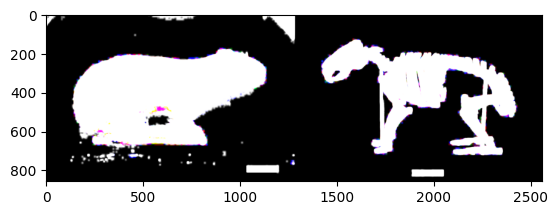

In [41]:
plt.imshow(image_lp) # uhoh...
plt.show()

Infelizmente, não era para ser =(

Você deve se lembrar que a imagem tinha valores entre $\Large [0, 255]$ e era do tipo `uint8`.

Quando a convolvemos, o tipo de dado tornou-se `float`, e agora a `matplotlib` está nos dizendo que nossa imagem é estranha.

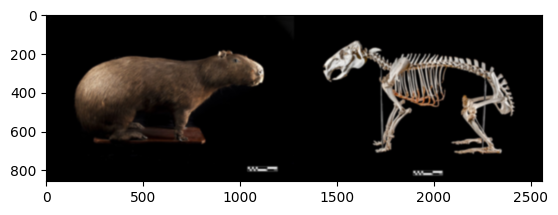

In [42]:
plt.imshow(image_lp / 255.0) # A maneira mais fácil é simplesmente dividir a imagem por 255
plt.show()

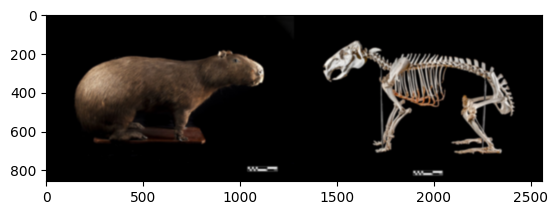

In [43]:
plt.imshow(image_lp.astype(np.uint8)) # Também podemos convertê-la de volta para uint8!
plt.show()

# 5. Domínio de frequência (Fourier)

Você deve ter notado que a convolução foi um pouco lenta.

Como a imagem é muito grande e o kernel também é muito grande, ela é bastante cara computacionalmente.

Uma maneira mais rápida poderia ser fazendo a convolução no domínio de Fourier!

Lembre-se que:

$$
\Large f*g = \mathcal{F}^{-1}\{F \cdot G\}
$$

In [44]:
# Calcule a transformada de Fourier da imagem
f_image_pil_r = np.fft.fft2(image_pil[:, :, 0])
f_image_pil_g = np.fft.fft2(image_pil[:, :, 1])
f_image_pil_b = np.fft.fft2(image_pil[:, :, 2])

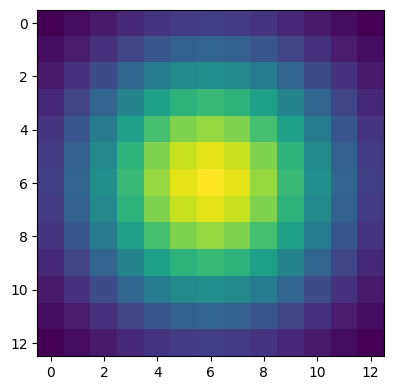

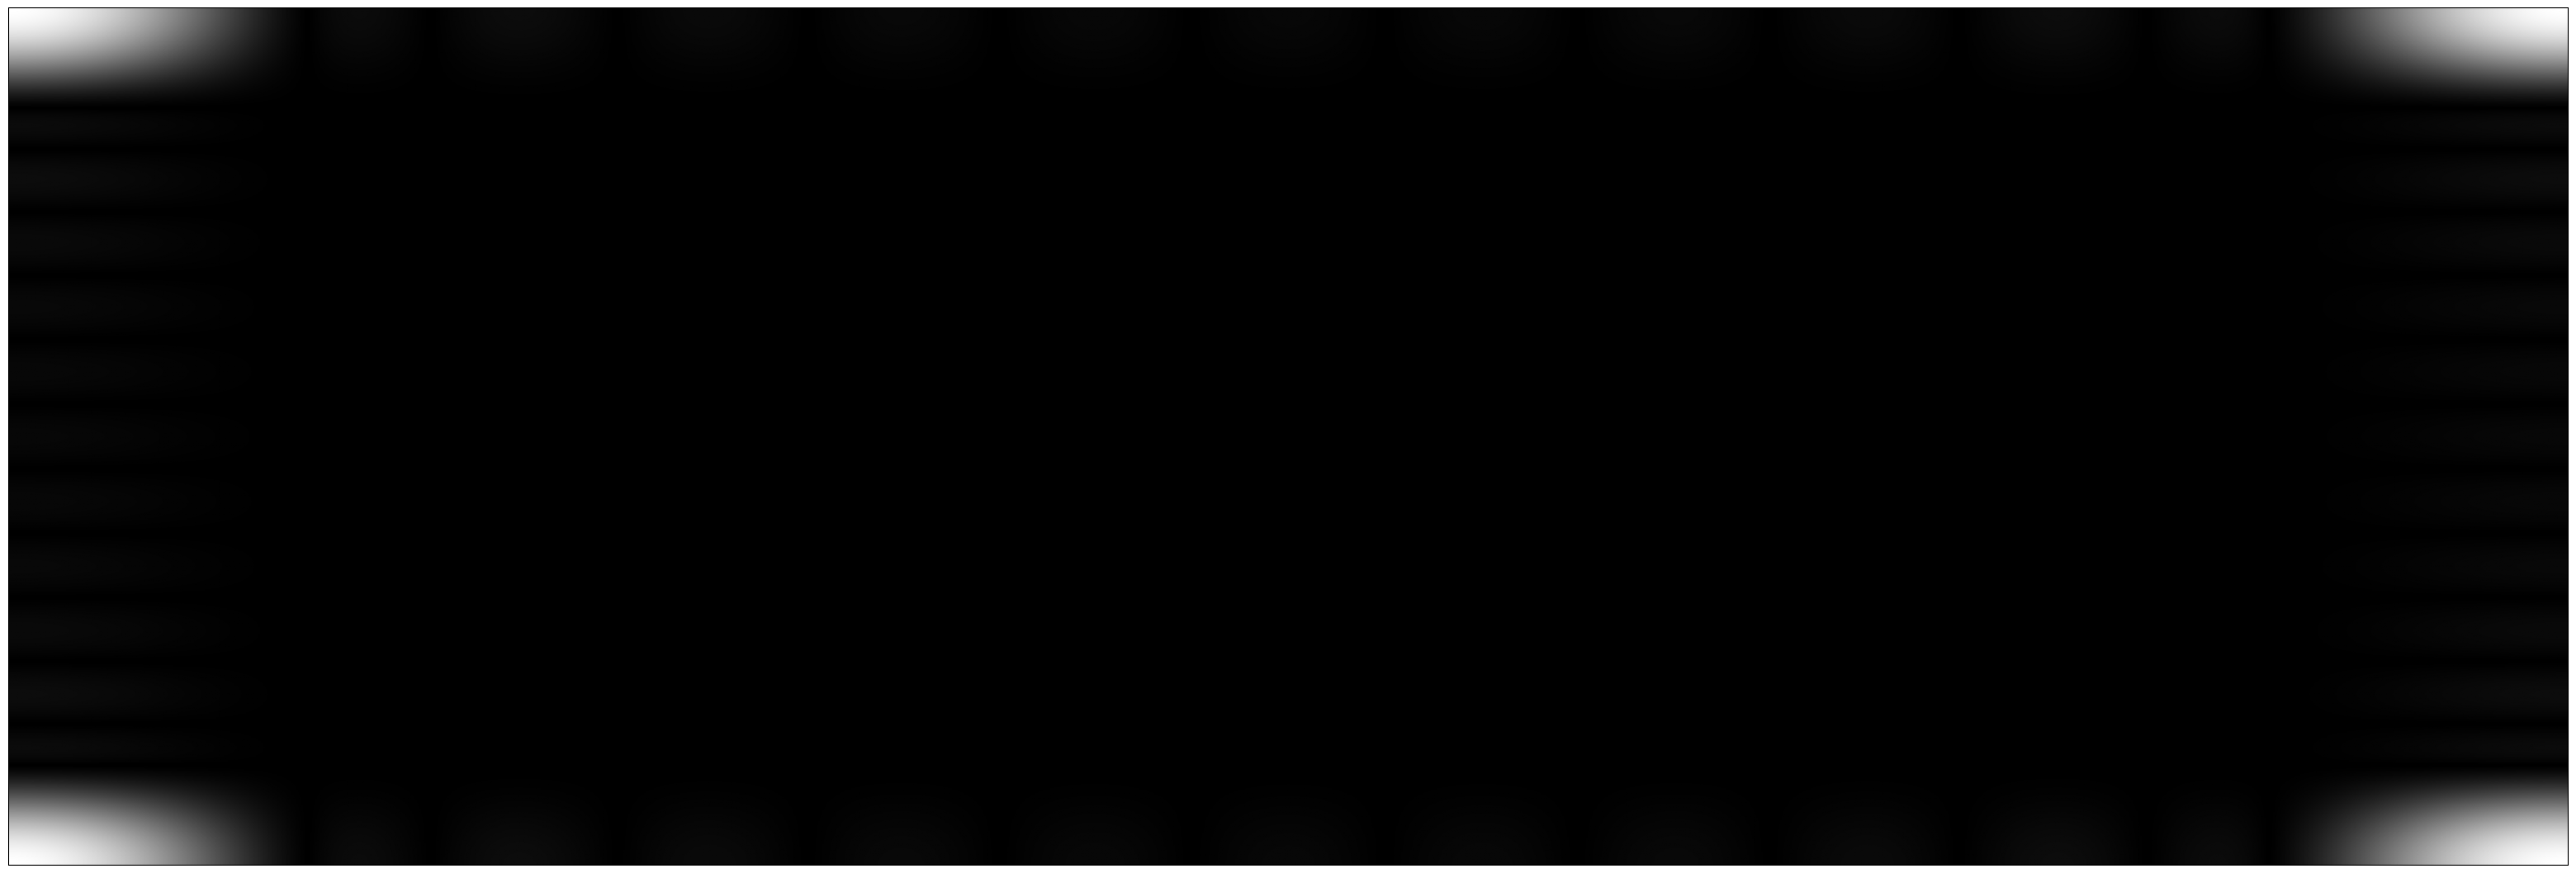

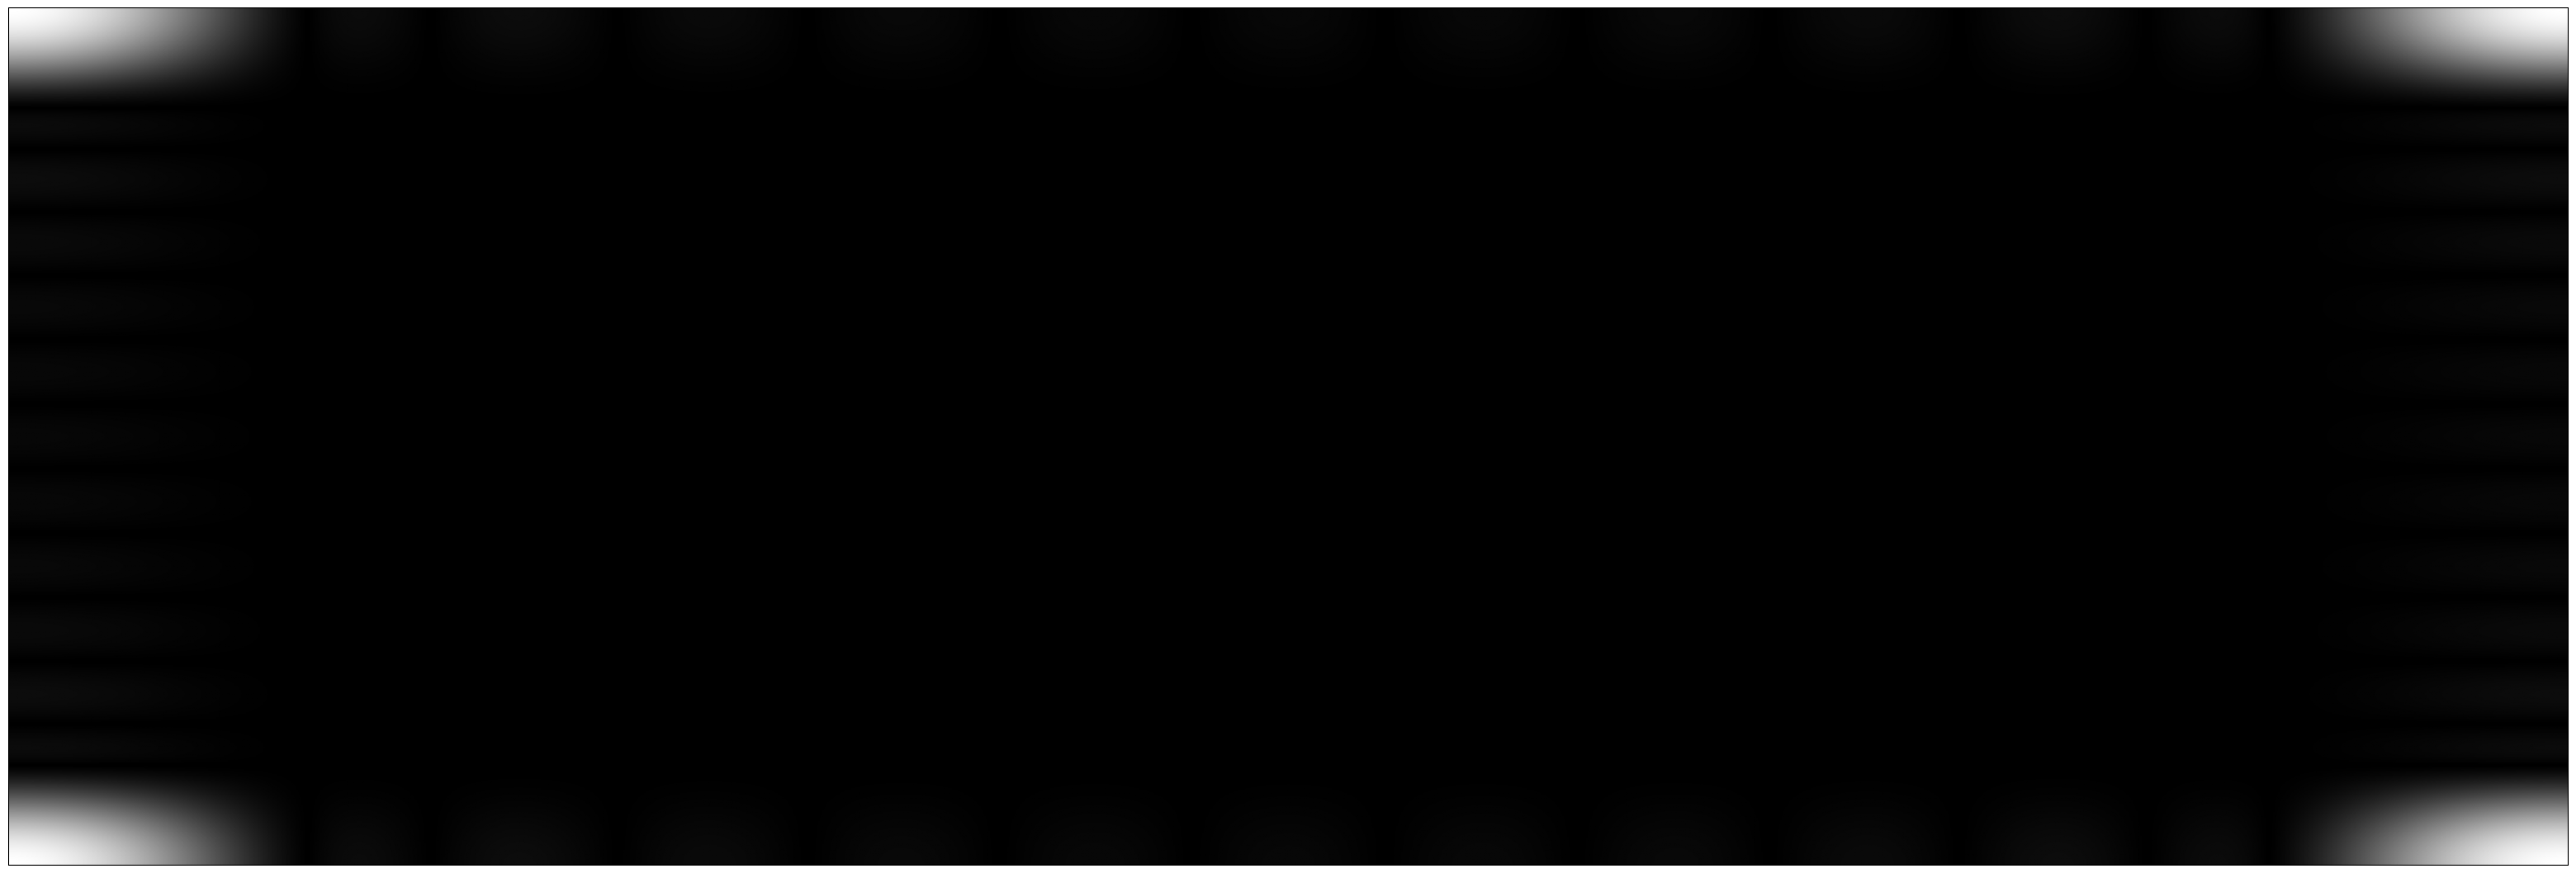

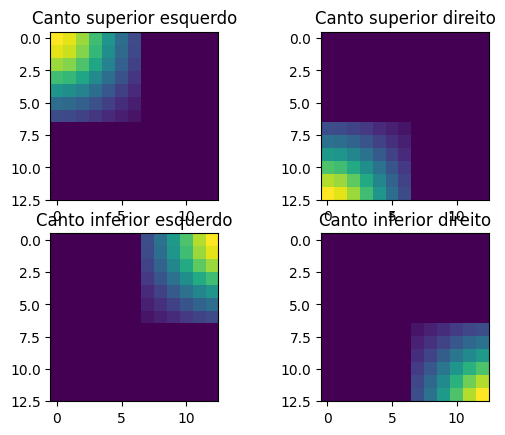

In [45]:
# Transformada de Fourier do filtro
# Note que o filtro DEVE TER o mesmo tamanho da imagem!!!
zero_padded_lp_filter = np.zeros(image_pil[:, :, 0].shape, dtype=float)

# Aqui nós deslocamos implicitamente o filtro (no canto superior esquerdo da imagem)
zero_padded_lp_filter[:kernel_size, :kernel_size] = lp_filter
plt.figure(figsize=(4.5, 4.5))
plt.imshow(zero_padded_lp_filter[:kernel_size, :kernel_size])

# Plot the (centralized) DFT magnitude spectrum on log scale
IM = np.fft.fft2(zero_padded_lp_filter)
# IM = np.fft.fftshift(IM)
IMmag = np.log(np.abs(IM) + 1) # FFT on log-scale

fig, ax = plt.subplots(figsize=(40, 40))
# ax = fig.gca()
plt.imshow(IMmag, cmap='gray')
ax.set_xticks([])
ax.set_yticks([])

# Então, precisamos colocá-lo de volta no lugar!
zero_padded_lp_filter = np.roll(zero_padded_lp_filter, shift=(-(kernel_size//2), -(kernel_size//2)), axis=(0,1))

# Plot the (centralized) DFT magnitude spectrum on log scale
IM = np.fft.fft2(zero_padded_lp_filter)
# IM = np.fft.fftshift(IM)
IMmag = np.log(np.abs(IM) + 1) # FFT on log-scale

fig = plt.figure(figsize=(40, 40))
ax = fig.gca()
plt.imshow(IMmag, cmap='gray')
ax.set_xticks([])
ax.set_yticks([])

plt.figure()
plt.subplot(2, 2, 1)
plt.imshow(zero_padded_lp_filter[:kernel_size, :kernel_size])
plt.title('Canto superior esquerdo')
plt.subplot(2, 2, 2)
plt.imshow(zero_padded_lp_filter[-kernel_size:, :kernel_size])
plt.title('Canto superior direito')
plt.subplot(2, 2, 3)
plt.imshow(zero_padded_lp_filter[:kernel_size, -kernel_size:])
plt.title('Canto inferior esquerdo')
plt.subplot(2, 2, 4)
plt.imshow(zero_padded_lp_filter[-kernel_size:, -kernel_size:])
plt.title('Canto inferior direito')
plt.show()

# Transformada de Fourir do filtro
f_lp_filter = np.fft.fft2(zero_padded_lp_filter)

**Tarefa**: Agora multiplique e faça a transformada inversa para cada canal!

*Dica*: A função da transformação inversa é `np.fft.ifft2`

In [46]:
# Responda aqui
image_lp_r_fast = np.fft.ifft2(f_image_pil_r * f_lp_filter)
image_lp_g_fast = np.fft.ifft2(f_image_pil_g * f_lp_filter)
image_lp_b_fast = np.fft.ifft2(f_image_pil_b * f_lp_filter)

**Tarefa**: Empilhe os canais como você fez anteriormente.

In [47]:
# Responda aqui
image_lp_fast = np.stack((image_lp_r_fast, image_lp_g_fast, image_lp_b_fast), axis=-1)

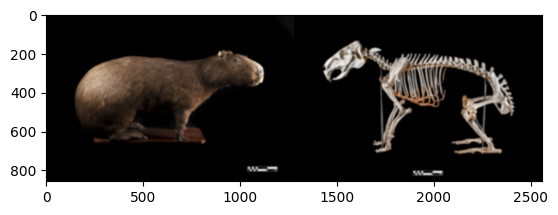

In [48]:
plt.imshow(np.clip(image_lp_fast.real, 0, 255).astype(np.uint8)) # Tambem podemos converte-lo de volta para uint8!
# Perceba que precisamos plotar somente a parte real de image_lp_fast que contem numeros complexos do tipo z = real + j*imag
# (o np.clip evita que erros de arredondamento, como -1e-13, virem 255 ao converter para uint8)
plt.show()

**Verifique**: Parece a imagem com as anteriores?

Diferenca maxima na imagem toda  : 7.841224721169706
Diferenca maxima longe das bordas: 2.5579538487363607e-13


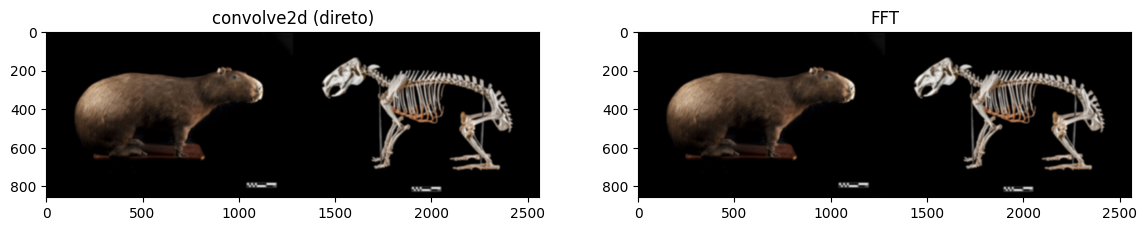

In [49]:
# Compara o resultado rapido (FFT) com o direto (convolve2d)
dif = np.abs(image_lp_fast.real - image_lp)
print('Diferenca maxima na imagem toda  :', dif.max())
print('Diferenca maxima longe das bordas:', dif[kernel_size:-kernel_size, kernel_size:-kernel_size].max())

fig, axs = plt.subplots(1, 2, figsize=(14, 3))
axs[0].imshow(image_lp.astype(np.uint8)); axs[0].set_title('convolve2d (direto)')
axs[1].imshow(np.clip(image_lp_fast.real, 0, 255).astype(np.uint8)); axs[1].set_title('FFT')
plt.show()

**Resposta:** sim, as duas imagens são visualmente iguais. Longe das bordas a diferença é da ordem de $10^{-12}$ (puro erro de arredondamento). Perto das bordas elas diferem um pouco: `convolve2d(mode='same')` considera que fora da imagem há zeros, enquanto a FFT faz uma convolução **circular**, em que a borda esquerda "enxerga" a borda direita (e a de cima enxerga a de baixo).

Isso foi basicamente o tutorial básico de processamento de imagens, no entanto, há ainda uma infinidade de coisas por saber.

Veja o compêndio de dicas de [`numpy`](http://datacamp-community-prod.s3.amazonaws.com/ba1fe95a-8b70-4d2f-95b0-bc954e9071b0)
e algumas [operações de álgebra linear mais avançadas](https://gist.github.com/Parskatt/18a7db9784a43aa598e59f21412b4ec2)

A seguir, vamos revisar alguns materiais que poderam ajudá-lo com os laboratórios da disciplina!

# 6. Material de apoio para os laboratórios

## 6.1 Laboratório 1
No Laboratório 1, você construirá um **filtro de derivadas regularizado**.

Este filtro decorre do [fato de que](https://en.wikipedia.org/wiki/Convolution#Differentiation):

$\Large \frac{\partial}{\partial x} (f*g(\sigma)) (x) = \left( f*\frac{\partial}{\partial x} g(\sigma) \right) ( x) = (f*\underbrace{\frac{-x}{\sigma^2} g(\sigma)}_{\text{d}f} ) (x)$

onde $\Large g = \exp \left( -\frac{x^2}{2\sigma^2} \right)$.

Então, usamos o filtro: $\Large \text{d}f = \frac{-x}{\sigma^2}g(\sigma)$ e o convolvemos com o nosso sinal $\Large f$.

Além disso, [***este filtro é separável quando está na sua versão 2D***](https://en.wikipedia.org/wiki/Separable_filter), o que é ótimo porque, dado que

$\Large \text{d}f(x,y) = \text{d}f(x)g(y)$

então

$\Large f * \text{d} f = (f * \text{d} f(x)) * g(y)$

Assim, podemos realizar nossa convolução 2D, que escala **quadraticamente** com o tamanho do *kernel* (*aka.* filtro), e compô-la em 2 convoluções separadas, que escalam apenas **linearmente**!

In [50]:
kernel_size = 7
sigma = 1.5
x = np.linspace(-(kernel_size//2), kernel_size//2, num=kernel_size)[np.newaxis, :] # Cria um vetor de tamanho 1xN (onde N é igual a kernel_size)
g = np.exp(-x**2 / (2 * sigma**2)) # Filtro Gaussiano 1-D
g = g / np.sum(g) # Filtro Gaussiano normalizado 1-D
df = -x * g / (sigma**2)

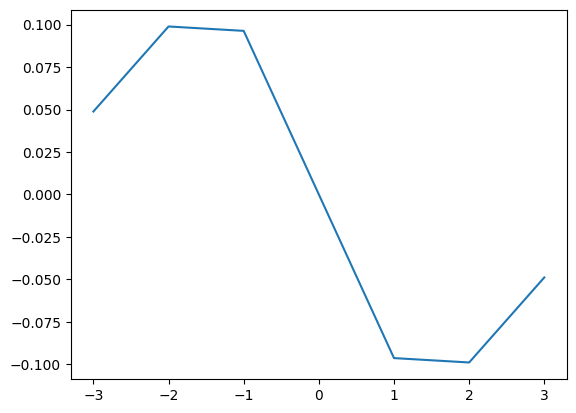

In [51]:
plt.plot(x[0], df[0])
plt.show()

É muuuuito importante que o nosso filtro seja **simétrico**.

**Tarefa**: Explique por quê o filtro não é simétrico se o tamanho do kernel for par!

*Dica*: Tente alterar o tamanho do kernel acima e veja o que acontece :)

In [52]:
for ks in [7, 6]:
    xk = np.linspace(-(ks//2), ks//2, num=ks)
    gk = np.exp(-xk**2 / (2 * 1.5**2)); gk = gk / gk.sum()
    print(f'kernel_size={ks}: posicoes = {xk}')
    print(f'                 df        = {np.round(-xk * gk / 1.5**2, 3)}\n')

kernel_size=7: posicoes = [-3. -2. -1.  0.  1.  2.  3.]
                 df        = [ 0.049  0.099  0.096 -0.    -0.096 -0.099 -0.049]

kernel_size=6: posicoes = [-3.  -1.8 -0.6  0.6  1.8  3. ]
                 df        = [ 0.058  0.126  0.08  -0.08  -0.126 -0.058]



**Resposta**:

Com `kernel_size` **ímpar** (7), as posições são `[-3, -2, -1, 0, 1, 2, 3]`: há um **elemento central** (posição 0) e posições **inteiras**, simétricas em torno de um pixel. O filtro fica exatamente "em cima" do pixel que está sendo calculado.

Com `kernel_size` **par** (6), `np.linspace(-3, 3, num=6)` dá `[-3, -1.8, -0.6, 0.6, 1.8, 3]`:

- **Não existe amostra central**: o centro do filtro cai **entre** dois pixels, e o resultado da convolução fica deslocado em meio pixel.
- As posições **deixam de ser inteiras**, então elas não correspondem mais à grade de pixels: o filtro é calculado em pontos que não existem na imagem, e o espaçamento (1.2) não é o de 1 pixel.
- Para uma máscara de tamanho par não dá para ser simétrica *e* alinhada à grade de pixels ao mesmo tempo. Para as derivadas isso importa, porque o `df` precisa ser perfeitamente anti-simétrico em torno do pixel central (`df[-i] = -df[i]`, valendo 0 no centro) para que a derivada seja medida na posição certa. Por isso se usam kernels com tamanho **ímpar**.

Abaixo, mostramos como realizar a convolução e a imagem da derivada resultante

In [53]:
image_pil = Image.open('capybaras.png')
image_pil_gray = np.mean(np.array(image_pil)[:, :, :3], axis=-1)  # media apenas dos canais R, G, B (sem o canal alfa)
dx = conv2(conv2(image_pil_gray, df, mode='same'), g.T, mode='same')
dy = conv2(conv2(image_pil_gray, df.T, mode='same'), g, mode='same')

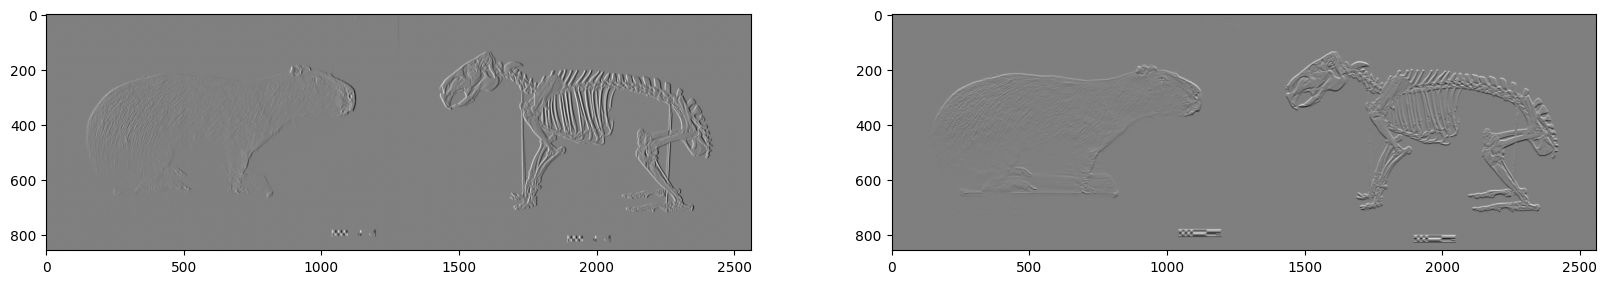

In [54]:
plt.figure(figsize=(20, 20))
plt.subplot(1, 2, 1)
plt.imshow(dx, cmap='gray')
plt.subplot(1, 2, 2)
plt.imshow(dy, cmap='gray')
plt.show()

## 6.2 Laboratório 2

No Laboratório 2 você usará a paleta de cores da função `gopimage` para visualização.

Ela utiliza uma complexa representação das imagens.

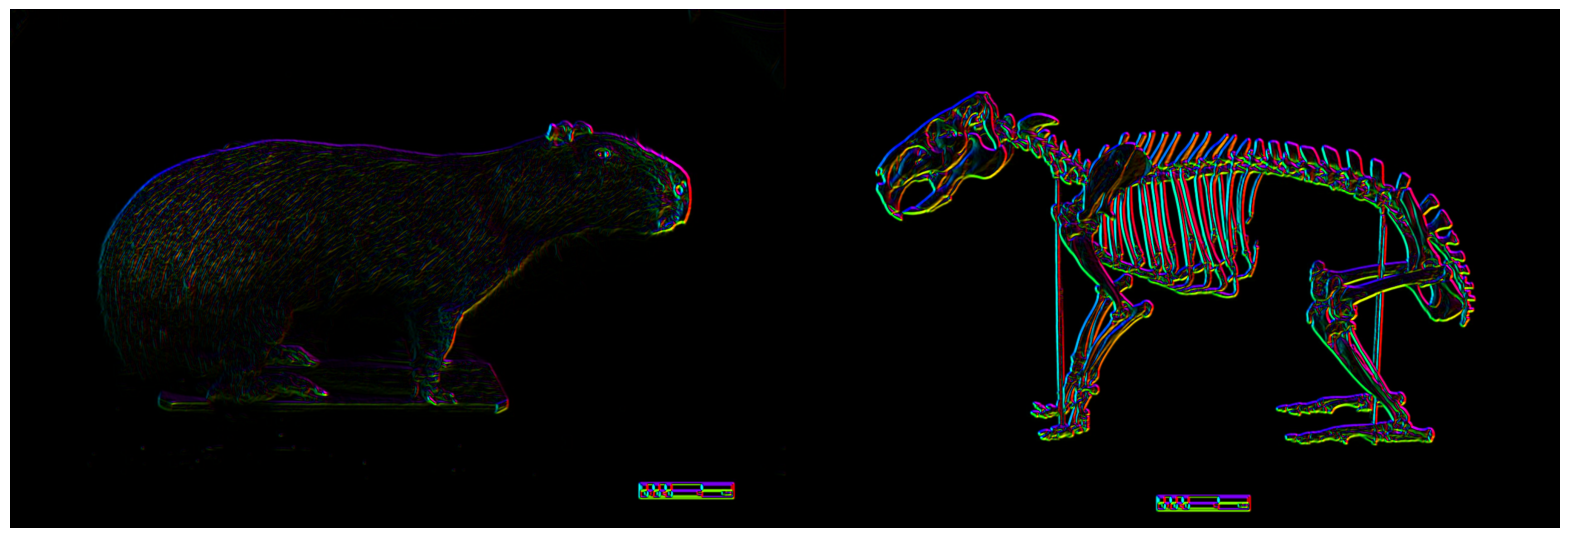

In [55]:
try:
    from INF0417 import gopimage
except ImportError:
    # Modulo da disciplina indisponivel: versao propria de gopimage.
    # Codifica um array complexo z como imagem colorida:
    #   - COR (matiz) = fase (angulo) de z
    #   - BRILHO      = modulo |z|
    from matplotlib.colors import hsv_to_rgb

    def gopimage(z, figsize=(10, 10)):
        z = np.asarray(z)
        hue = (np.angle(z) + np.pi) / (2 * np.pi)            # [-pi, pi] -> [0, 1]
        val = np.clip(np.abs(z) / np.percentile(np.abs(z), 99), 0, 1)
        rgb = hsv_to_rgb(np.stack([hue, np.ones_like(hue), val], axis=-1))

        plt.figure(figsize=figsize)
        plt.imshow(rgb)
        plt.axis('off')
        plt.show()

z = dx + 1j*dy

gopimage(z, figsize=(20, 20)) # Voce deve ver (partes de) uma capivara colorida e ruidosa

Enquanto a imagem acima é muito bonita, ela é bastante ruidosa!

Em vez disso, podemos olhar para uma representação melhor, *e.g.*, o ***tensor de estrutura***!

In [56]:
# (float em vez de np.zeros_like(image_pil), que seria uint8 e truncaria/estouraria os valores)
T = np.zeros(dx.shape + (3,), dtype=float)
Tlp = np.zeros_like(T)
T[:, :, 0] = dx * dx
T[:, :, 1] = dx * dy
T[:, :, 2] = dy * dy

In [57]:
sigma = 1.0
kernel_size = 25
lp = np.exp(-0.5*(np.linspace(-(kernel_size//2), kernel_size//2, num=kernel_size) / sigma)**2)[np.newaxis, :]
lp = lp / np.sum(lp) # Normaliza o filtro
Tlp[:, :, 0] = conv2(conv2(T[:, :, 0], lp, mode ='same'), lp.T, mode ='same')
Tlp[:, :, 1] = conv2(conv2(T[:, :, 1], lp, mode ='same'), lp.T, mode ='same')
Tlp[:, :, 2] = conv2(conv2(T[:, :, 2], lp, mode ='same'), lp.T, mode ='same')

In [58]:
z = Tlp[:, :, 0] - Tlp[:, :, 2] + 2j*Tlp[:, :, 1]

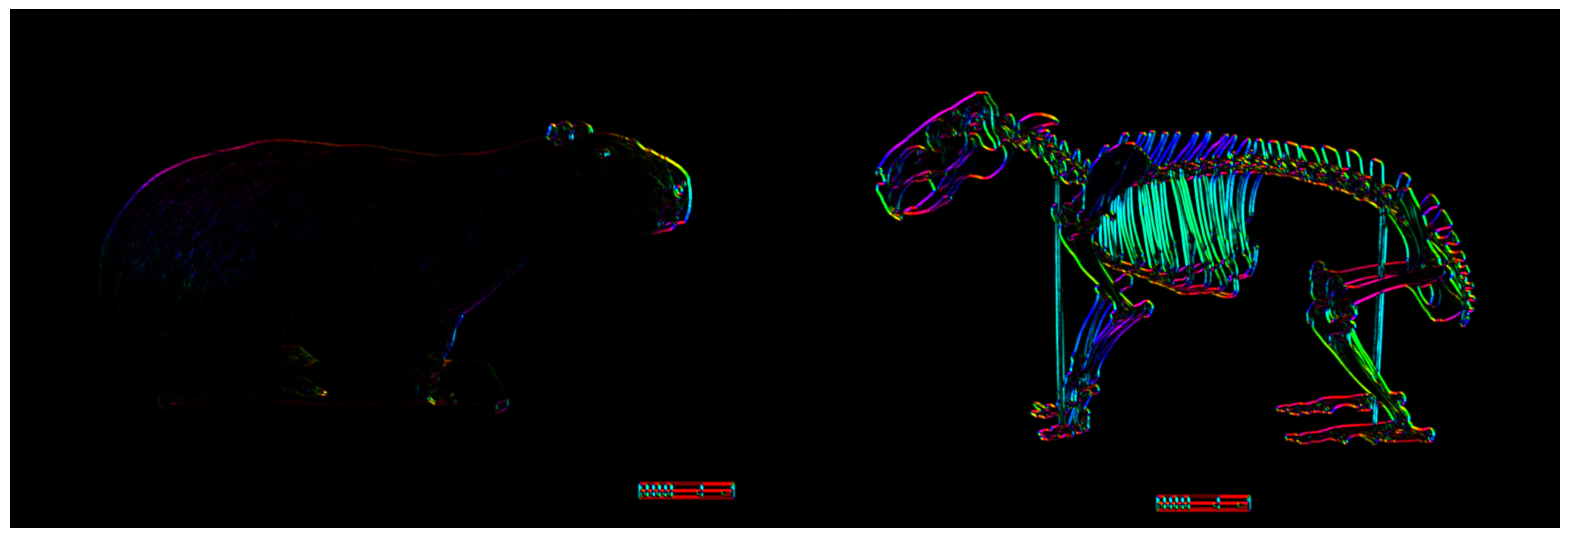

In [59]:
gopimage(z, figsize=(20, 20)) # Você deve ver (partes de) uma capivara colorida

Observe que as cores aqui podem ser ligeiramente diferentes do que é o apresentado em aula.

Uma diferença pode vir do fato de que o eixo $y$ é direcionado para abaixo.

**Tarefa**: Altere a direção do eixo $y$ (*e.g.*, invertendo a direção do filtro) e plote $z$ novamente. O que acontece?

In [60]:
# Escreva aqui a resposta
dx = conv2(conv2(image_pil_gray, df, mode='same'), g.T, mode='same')
dy = conv2(conv2(image_pil_gray, -df.T, mode='same'), g, mode='same')   # filtro invertido: eixo y para cima

T = np.zeros(dx.shape + (3,), dtype=float)
Tlp = np.zeros_like(T)
T[:, :, 0] = dx * dx
T[:, :, 1] = dx * dy
T[:, :, 2] = dy * dy

In [61]:
sigma = 1.0
kernel_size = 25
lp = np.exp(-0.5*(np.linspace(-(kernel_size//2), kernel_size//2, num=kernel_size) / sigma)**2)[np.newaxis, :]
lp = lp / np.sum(lp) # Normaliza o filtro
Tlp[:, :, 0] = conv2(conv2(T[:, :, 0], lp, mode ='same'), lp.T, mode ='same')
Tlp[:, :, 1] = conv2(conv2(T[:, :, 1], lp, mode ='same'), lp.T, mode ='same')
Tlp[:, :, 2] = conv2(conv2(T[:, :, 2], lp, mode ='same'), lp.T, mode ='same')

In [62]:
z = Tlp[:, :, 0] - Tlp[:, :, 2] + 2j*Tlp[:, :, 1]

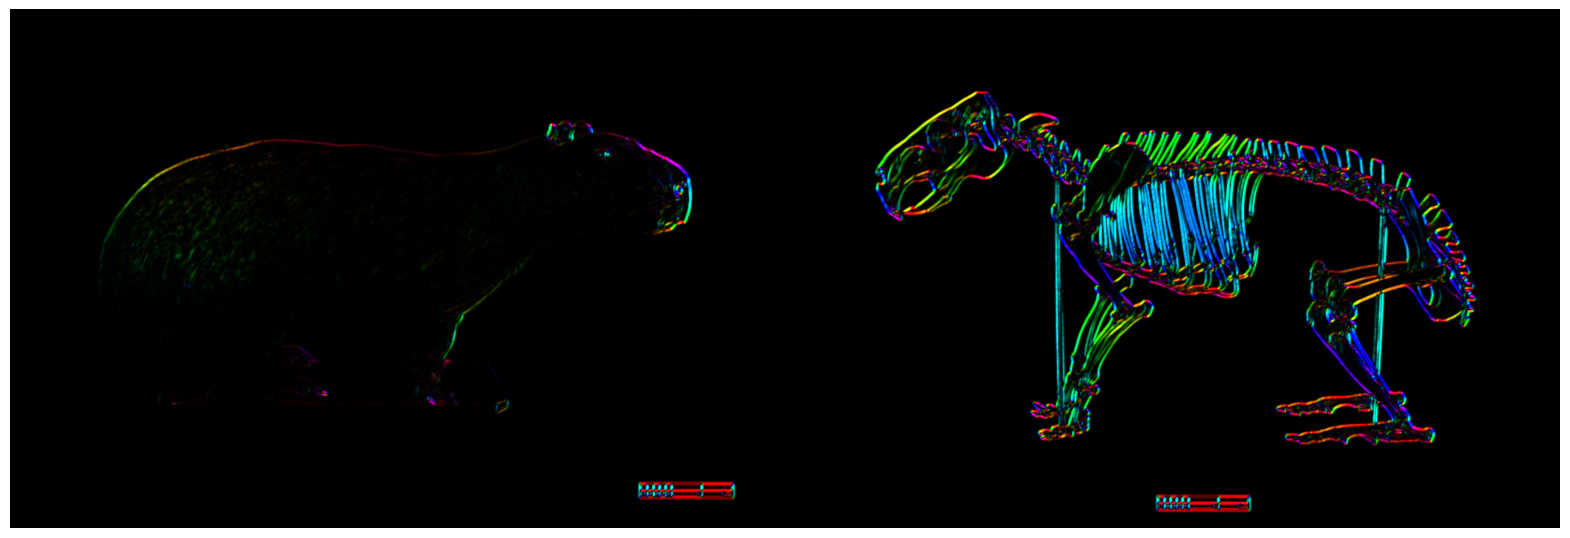

In [63]:
gopimage(z, figsize=(20, 20)) # Você deve ver (partes de) uma capivara colorida

**Resposta**:

Ao inverter o filtro, `dy` troca de sinal (`dy → -dy`). Com isso, $T_{xy} = d_x d_y$ também troca de sinal, enquanto $T_{xx}$ e $T_{yy}$ ficam iguais. Logo,

$$
z = T_{xx} - T_{yy} + 2j\,T_{xy} \;\longrightarrow\; \bar{z}
$$

vira o **complexo conjugado**: o módulo (o brilho) não muda, mas a **fase** (a cor) troca de sinal, $\theta \to -\theta$. O resultado é o **espelhamento das cores** em relação ao eixo horizontal no círculo de cores: bordas horizontais e verticais mantêm as cores, e bordas inclinadas a +45° e -45° **trocam** de cor entre si.
A estrutura da imagem é a mesma. O que muda é a convenção: sem a inversão, o eixo $y$ aponta para baixo (convenção de imagem), e com ela aponta para cima (convenção matemática).

**Tarefa**: O que acontece quando você aumenta o valor de `sigma`? O que acontece se você diminuir ele? Por quê?

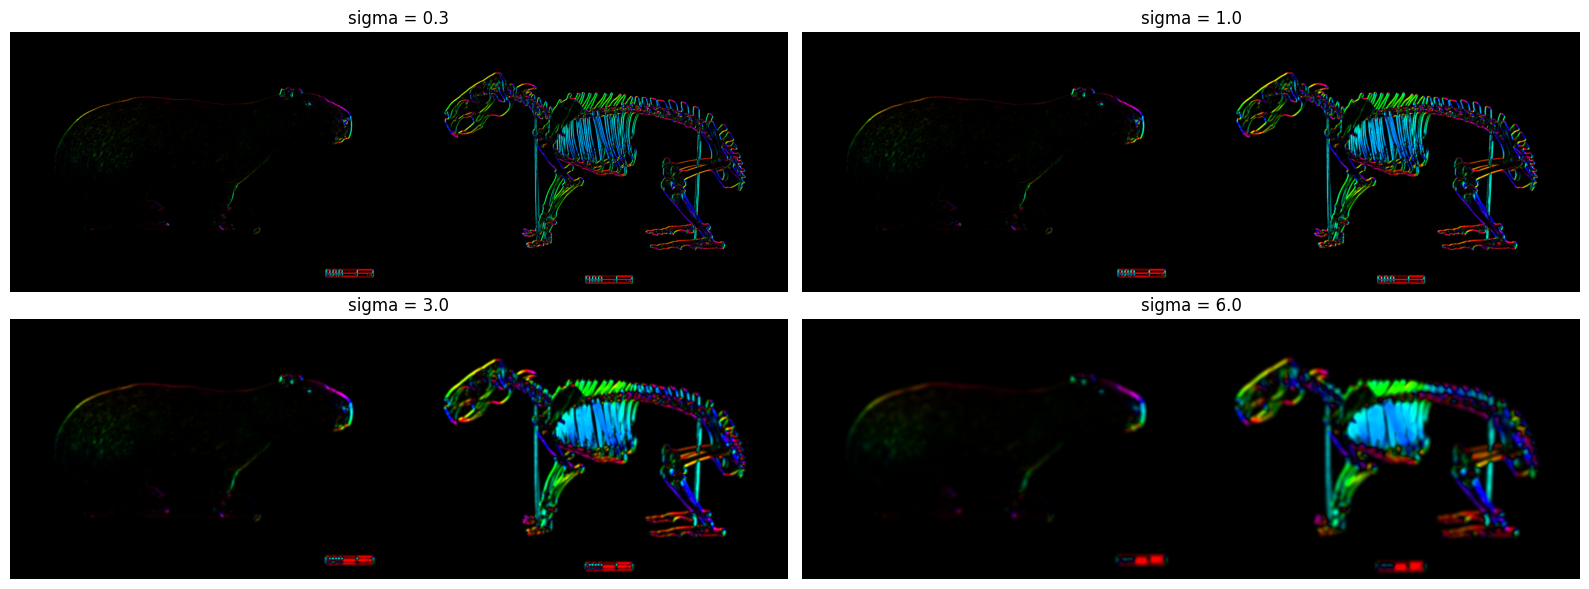

In [64]:
def tensor_estrutura(sigma, kernel_size=25):
    c = np.linspace(-(kernel_size//2), kernel_size//2, num=kernel_size)
    lp = np.exp(-0.5 * (c / sigma)**2)[np.newaxis, :]
    lp = lp / np.sum(lp)
    suav = lambda a: conv2(conv2(a, lp, mode='same'), lp.T, mode='same')
    return suav(dx*dx) - suav(dy*dy) + 2j*suav(dx*dy)

from matplotlib.colors import hsv_to_rgb
fig, axs = plt.subplots(2, 2, figsize=(16, 6))
for ax, s in zip(axs.ravel(), [0.3, 1.0, 3.0, 6.0]):
    zs = tensor_estrutura(s)
    rgb = hsv_to_rgb(np.stack([(np.angle(zs) + np.pi)/(2*np.pi), np.ones(zs.shape),
                               np.clip(np.abs(zs)/np.percentile(np.abs(zs), 99), 0, 1)], axis=-1))
    ax.imshow(rgb); ax.set_title(f'sigma = {s}'); ax.axis('off')
plt.tight_layout(); plt.show()

**Resposta**:

O `sigma` controla **quantos pixels vizinhos são promediados** ao suavizar o tensor de estrutura (o filtro passa-baixa `lp`).

- **Aumentar `sigma`**: a média é feita sobre uma região maior. As orientações dos pixels vizinhos se combinam, o ruído é cancelado e o campo de orientação (as cores) fica **mais suave e coerente**, com regiões de cor uniforme ao longo de bordas e texturas. Em compensação, **detalhes finos se perdem** e as bordas ficam "borradas", com regiões de orientações diferentes misturadas (perde resolução espacial). Se `sigma` ficar muito grande (acima de ~4), a janela de 25 pontos passa a truncar o filtro, e então convém aumentar também o `kernel_size`.
- **Diminuir `sigma`**: o filtro se aproxima de um impulso (praticamente não suaviza). O resultado é parecido com o do gradiente bruto: **muito detalhe, mas muito ruído**, com cores variando de pixel a pixel.

Isso é o compromisso clássico entre **resolução espacial** (sigma pequeno) e **robustez ao ruído** (sigma grande). O tensor de estrutura é útil justamente porque promedia o produto `dx*dy` em vez de promediar o gradiente, e o gradiente puro se cancelaria, porque `dx` e `dy` mudam de sinal entre os dois lados de uma borda.